# CardioAI — Fase 6: Coração Sob Controle
## Sistema Preditivo e Multiagente para Eventos Cardíacos

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jonsilva91/CardioAI/blob/main/phases/fase06_preditivo_multiagente/notebooks/fase06_modelo_pico_risco_colab.ipynb)

---

### Integrantes do Grupo:
- **Jonas Luis da Silva** — RM561465
- **Edson Henrique Felix Batista** — RM566321

**Curso:** Inteligência Artificial & Engenharia de Software — FIAP  
**Etapa:** Fase 6 — Modelo Preditivo de Pico de Risco e Orquestração Multiagente

---

### Objetivo deste Notebook:
1. **Gerar a base de dados sintética realista** reproduzindo o código oficial da FIAP (`seed=42, n=5000`);
2. **Explorar a base de dados (EDA)**, verificando o balanceamento de classes (~73%/27%) e distribuição das variáveis;
3. **Treinar e comparar dois modelos supervisionados**:
   - Baseline: *Regressão Logística* (com padronização *StandardScaler* em Pipeline);
   - Modelo Principal: *Random Forest Classifier* (com 200 árvores de decisão);
4. **Avaliar detalhadamente o desempenho**: Acurácia, Precisão, Recall, F1-Score da Classe 1, Relatório de Classificação e Matriz de Confusão;
5. **Calcular a Importância das Features** e analisar o papel das variáveis ativas vs. variáveis de ruído;
6. **Executar Validação Cruzada Estratificada (5 Folds)** para atestar a generalização;
7. **Persistir o modelo treinado** em formato `joblib` com metadados para integração com os agentes;
8. **Simular a inferência de um novo paciente (`novo_caso`)** e acionar deterministicamente a base de protocolos clínicos.

### 1. Importação das Bibliotecas Essenciais

In [1]:
import os
import sys
from datetime import datetime
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | NumPy: {np.__version__} | Scikit-Learn: {sklearn.__version__}")

Python: 3.12.10 | Pandas: 2.2.3 | NumPy: 2.2.6 | Scikit-Learn: 1.9.0


### 2. Geração da Base de Dados Sintética

O código abaixo reproduz **exatamente** o trecho fornecido no enunciado oficial da FIAP:
- Fixação da semente pseudoaleatória `np.random.seed(42)`
- 5.000 amostras simuladas representando registros clínicos e operacionais
- Cálculo de `risk_score` baseado em 6 critérios clínicos e criação do rótulo binário `pico_risco = (risk_score >= 2)`.

In [2]:
np.random.seed(42)
n = 5000

df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n)
})

risk_score = (
    (df["carga_sistema"] > 80).astype(int) +
    (df["tempo_espera"] > 60).astype(int) +
    (df["spo2_media"] < 92).astype(int) +
    (df["fc_media"] > 110).astype(int) +
    (df["eventos_24h"] > 4).astype(int) +
    (df["disponibilidade_recursos"] < 40).astype(int)
)

df["pico_risco"] = (risk_score >= 2).astype(int)

print(f"Dimensões do dataset gerado: {df.shape}")
df.head()

Dimensões do dataset gerado: (5000, 11)


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0


### 3. Análise Exploratória dos Dados (EDA)

Vamos analisar a distribuição estatística das 10 variáveis e checar o balanceamento das classes.

,count,mean,std,min,25%,50%,75%,max
idade_media,5000.0,55.058872,11.925581,18.000000,47.105140,55.161587,62.992127,90.000000
carga_sistema,5000.0,64.637825,19.987923,30.003698,47.604462,64.430649,81.684947,99.977124
tempo_espera,5000.0,45.243077,19.383549,5.000000,31.838260,45.143356,58.278490,113.578210
fc_media,5000.0,85.305275,14.897908,50.000000,75.000614,85.218044,95.604945,150.000000
spo2_media,5000.0,94.920231,2.874954,83.430874,92.900337,94.984043,97.009198,100.000000
pa_sistolica,5000.0,124.893487,19.529416,80.000000,111.201401,125.058077,138.054290,198.832490
temperatura,5000.0,24.003366,5.080669,10.000000,20.514351,23.967477,27.506223,40.000000
densidade_eventos,5000.0,2.998000,1.731876,0.000000,2.000000,3.000000,4.000000,13.000000
eventos_24h,5000.0,1.992400,1.418430,0.000000,1.000000,2.000000,3.000000,9.000000
disponibilidade_recursos,5000.0,60.271841,23.030132,20.035489,40.186700,60.871675,80.393247,99.989376


DISTRIBUIÇÃO DA VARIÁVEL ALVO (pico_risco):
Classe 0 (Sem pico): 3671 registros (73.42%)
Classe 1 (Pico de risco): 1329 registros (26.58%)


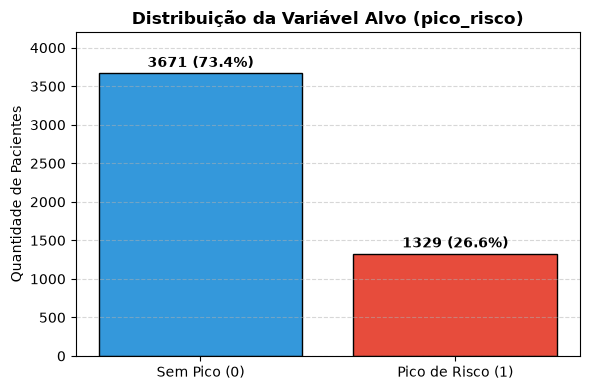

In [3]:
# Estatísticas descritivas básicas
display(df.describe().T)

# Contagem e proporção das classes
contagem = df["pico_risco"].value_counts()
proporcao = df["pico_risco"].value_counts(normalize=True) * 100

print("=" * 60)
print("DISTRIBUIÇÃO DA VARIÁVEL ALVO (pico_risco):")
print(f"Classe 0 (Sem pico): {contagem[0]} registros ({proporcao[0]:.2f}%)")
print(f"Classe 1 (Pico de risco): {contagem[1]} registros ({proporcao[1]:.2f}%)")
print("=" * 60)

# Gráfico de balanceamento
plt.figure(figsize=(6, 4))
plt.bar(["Sem Pico (0)", "Pico de Risco (1)"], contagem.values, color=["#3498db", "#e74c3c"], edgecolor="black")
plt.title("Distribuição da Variável Alvo (pico_risco)", fontsize=12, fontweight="bold")
plt.ylabel("Quantidade de Pacientes")
for i, v in enumerate(contagem.values):
    plt.text(i, v + 80, f"{v} ({proporcao[i]:.1f}%)", ha="center", fontweight="bold")
plt.ylim(0, 4200)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 4. Preparação dos Dados e Divisão Treino / Teste

As 10 features são definidas em ordem fixa. O particionamento é realizado na proporção **80% treino / 20% teste**, com estratificação pela variável dependente (`stratify=y`) e `random_state=42`.

In [4]:
FEATURES = [
    "idade_media",
    "carga_sistema",
    "tempo_espera",
    "fc_media",
    "spo2_media",
    "pa_sistolica",
    "temperatura",
    "densidade_eventos",
    "eventos_24h",
    "disponibilidade_recursos"
]

X = df[FEATURES]
y = df["pico_risco"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Total Geral: {len(X)}")
print(f"Conjunto de Treinamento: {X_train.shape[0]} amostras ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Conjunto de Teste:        {X_test.shape[0]} amostras ({X_test.shape[0]/len(X)*100:.0f}%)")

Total Geral: 5000
Conjunto de Treinamento: 4000 amostras (80%)
Conjunto de Teste:        1000 amostras (20%)


### 5. Treinamento dos Modelos de Machine Learning

Compararemos dois modelos clássicos vistos em aula:
1. **Regressão Logística (Baseline)**: Modelo linear com `StandardScaler` em pipeline;
2. **Random Forest Classifier**: Ensemble de 200 árvores de decisão.

In [5]:
# 1. Regressão Logística com Normalização (Pipeline)
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

# 2. Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)

print("Treinamento concluído com sucesso!")

Treinamento concluído com sucesso!


### 6. Avaliação e Comparação de Métricas no Teste

No contexto de saúde, a métrica mais crítica é o **Recall e F1 da Classe 1 (Pico de Risco)**, pois o erro mais grave é o **Falso Negativo** (deixar de identificar um paciente à beira de um colapso cardiovascular).

In [6]:
def calcular_metricas(y_true, y_pred):
    return {
        "Acurácia": accuracy_score(y_true, y_pred),
        "Precisão (1)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (1)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-Score (1)": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

m_lr = calcular_metricas(y_test, y_pred_lr)
m_rf = calcular_metricas(y_test, y_pred_rf)

df_comparativo = pd.DataFrame([m_lr, m_rf], index=["Regressão Logística (Baseline)", "Random Forest Classifier"])
display(df_comparativo.style.format("{:.4f}").highlight_max(color="#d4edda", axis=0))

print("\nRelatório Detalhado - Random Forest:")
print(classification_report(y_test, y_pred_rf, target_names=["Sem Pico (0)", "Pico de Risco (1)"]))

,Acurácia,Precisão (1),Recall (1),F1-Score (1)
Regressão Logística (Baseline),0.8160,0.6934,0.5526,0.6151
Random Forest Classifier,0.9990,1.0000,0.9962,0.9981



Relatório Detalhado - Random Forest:
                   precision    recall  f1-score   support

     Sem Pico (0)       1.00      1.00      1.00       734
Pico de Risco (1)       1.00      1.00      1.00       266

         accuracy                           1.00      1000
        macro avg       1.00      1.00      1.00      1000
     weighted avg       1.00      1.00      1.00      1000



### 7. Matriz de Confusão

Abaixo geramos a matriz de confusão gráfica do Random Forest para visualizar os verdadeiros e falsos positivos/negativos.

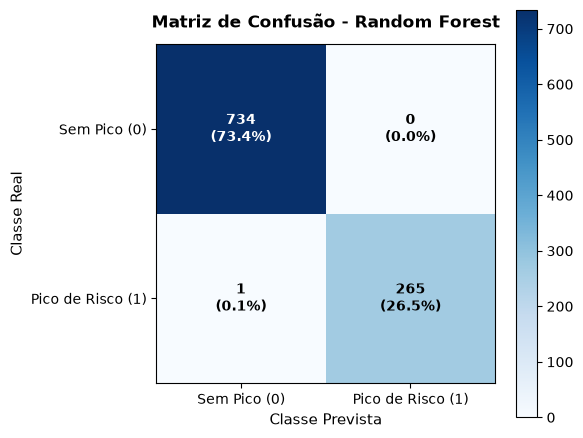

Verdadeiros Negativos (TN): 734
Falsos Positivos (FP):       0
Falsos Negativos (FN):       1
Verdadeiros Positivos (TP): 265


In [7]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Matriz de Confusão - Random Forest", fontsize=12, fontweight="bold", pad=12)
plt.colorbar()

classes = ["Sem Pico (0)", "Pico de Risco (1)"]
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, fontsize=10)
plt.yticks(tick_marks, classes, fontsize=10)

total = np.sum(cm)
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        pct = (val / total) * 100
        plt.text(
            j, i, f"{val}\n({pct:.1f}%)",
            ha="center", va="center",
            color="white" if val > thresh else "black",
            fontweight="bold"
        )

plt.ylabel("Classe Real", fontsize=11)
plt.xlabel("Classe Prevista", fontsize=11)
plt.tight_layout()
plt.show()

print(f"Verdadeiros Negativos (TN): {cm[0, 0]}")
print(f"Falsos Positivos (FP):       {cm[0, 1]}")
print(f"Falsos Negativos (FN):       {cm[1, 0]}")
print(f"Verdadeiros Positivos (TP): {cm[1, 1]}")

### 8. Importância das Features (Feature Importance)

O gráfico abaixo ilustra a importância de cada variável calculada pelo Random Forest.

> **Reflexão Acadêmica Importante:**
> As 6 variáveis que compõem o `risk_score` (`carga_sistema`, `tempo_espera`, `spo2_media`, `fc_media`, `eventos_24h`, `disponibilidade_recursos`) concentram a quase totalidade da importância.
> As outras 4 variáveis (`idade_media`, `pa_sistolica`, `temperatura`, `densidade_eventos`) são puro ruído para o classificador, mas são essenciais para os **protocolos clínicos**!

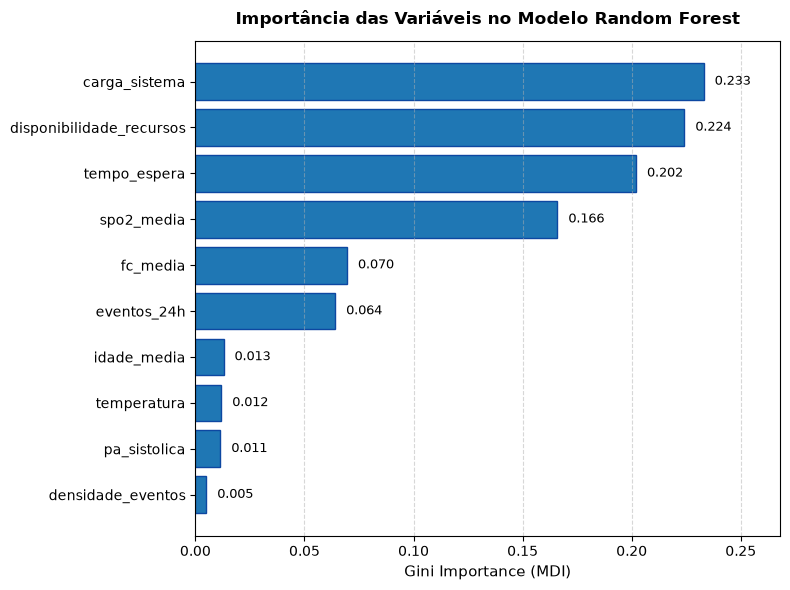

In [8]:
importancias = rf_clf.feature_importances_
indices = np.argsort(importancias)
sorted_features = [FEATURES[i] for i in indices]
sorted_importances = importancias[indices]

plt.figure(figsize=(8, 6))
bars = plt.barh(range(len(sorted_features)), sorted_importances, color="#1f77b4", edgecolor="#0d47a1")
plt.yticks(range(len(sorted_features)), sorted_features, fontsize=10)
plt.xlabel("Gini Importance (MDI)", fontsize=11)
plt.title("Importância das Variáveis no Modelo Random Forest", fontsize=12, fontweight="bold", pad=12)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=9)

plt.xlim(0, max(sorted_importances) * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 9. Validação Cruzada Estratificada (5 Folds)

Garante que o modelo não sofreu viés de amostragem na separação inicial de treino e teste.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(rf_clf, X, y, cv=cv, scoring="accuracy")
cv_f1 = cross_val_score(rf_clf, X, y, cv=cv, scoring="f1")

print("=" * 60)
print("RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLDS STRATIFIED):")
print(f"Acurácia Média: {cv_acc.mean():.4f} (± {cv_acc.std():.4f})")
print(f"F1-Score Médio: {cv_f1.mean():.4f} (± {cv_f1.std():.4f})")
print("=" * 60)

RESULTADOS DA VALIDAÇÃO CRUZADA (5-FOLDS STRATIFIED):
Acurácia Média: 0.9978 (± 0.0019)
F1-Score Médio: 0.9958 (± 0.0037)


### 10. Persistência do Modelo com Joblib

Empacotamos o modelo vencedor junto com a lista de features e metadados de governança.

In [10]:
caminho_salvamento = "modelo_pico_risco.joblib"

pacote_modelo = {
    "model": rf_clf,
    "model_name": "RandomForestClassifier",
    "features": FEATURES,
    "metrics": {
        "accuracy": float(m_rf["Acurácia"]),
        "precision_class_1": float(m_rf["Precisão (1)"]),
        "recall_class_1": float(m_rf["Recall (1)"]),
        "f1_class_1": float(m_rf["F1-Score (1)"]),
        "cv_accuracy_mean": float(cv_acc.mean()),
        "cv_f1_mean": float(cv_f1.mean()),
    },
    "trained_at": datetime.now().isoformat(),
    "sklearn_version": sklearn.__version__,
}

joblib.dump(pacote_modelo, caminho_salvamento)
print(f"Modelo salvo com sucesso em: {caminho_salvamento}")

# Download automático se executado dentro do ambiente Google Colab
try:
    from google.colab import files
    files.download(caminho_salvamento)
    print("Download disparado via Google Colab.")
except ImportError:
    print("Execução local: download automático via Colab ignorado.")

Modelo salvo com sucesso em: modelo_pico_risco.joblib
Execução local: download automático via Colab ignorado.


### 11. Simulação com o Paciente do Enunciado (`novo_caso`)

Testamos a inferência para o paciente fornecido no enunciado e acionamos a base de protocolos clínicos.

In [11]:
# Dados do paciente do enunciado (corrigindo a chave com espaço para underscore)
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade_recursos": 25  # Chave normalizada
}])

# Garante a ordem correta das features
novo_caso = novo_caso[FEATURES]

# Inferência de probabilidade e classe
prob_pico = float(rf_clf.predict_proba(novo_caso)[0, 1])
classe_pred = int(rf_clf.predict(novo_caso)[0])

# Classificação por limiares
if prob_pico < 0.40:
    classificacao = "BAIXO"
elif prob_pico < 0.70:
    classificacao = "MODERADO"
else:
    classificacao = "ALTO"

# Base de protocolos oficial
PROTOCOLOS = [
    "Se SPO2 < 88% → iniciar suporte respiratório imediato",
    "Se carga do sistema > 85% → abrir unidades temporárias",
    "Se FC > 120 → iniciar monitoramento intensivo",
    "Se eventos_24h > 5 → ativar equipe de resposta rápida",
    "Se disponibilidade_recursos < 30% → redistribuir insumos",
    "Se tempo_espera > 90 min → priorizar triagem emergencial",
    "Se temperatura > 38°C média → iniciar protocolo infeccioso",
    "Se densidade_eventos > 6 → ativar plano de contingência",
    "Se PA sistólica < 90 → iniciar protocolo de choque",
    "Se risco sistêmico alto → ativar estado de emergência"
]

# Avaliação determinística das regras
p_dict = novo_caso.iloc[0].to_dict()
protocolos_acionados = []

if p_dict["spo2_media"] < 88:
    protocolos_acionados.append(PROTOCOLOS[0])
if p_dict["carga_sistema"] > 85:
    protocolos_acionados.append(PROTOCOLOS[1])
if p_dict["fc_media"] > 120:
    protocolos_acionados.append(PROTOCOLOS[2])
if p_dict["eventos_24h"] > 5:
    protocolos_acionados.append(PROTOCOLOS[3])
if p_dict["disponibilidade_recursos"] < 30:
    protocolos_acionados.append(PROTOCOLOS[4])
if p_dict["tempo_espera"] > 90:
    protocolos_acionados.append(PROTOCOLOS[5])
if p_dict["temperatura"] > 38:
    protocolos_acionados.append(PROTOCOLOS[6])
if p_dict["densidade_eventos"] > 6:
    protocolos_acionados.append(PROTOCOLOS[7])
if p_dict["pa_sistolica"] < 90:
    protocolos_acionados.append(PROTOCOLOS[8])
if classificacao == "ALTO":
    protocolos_acionados.append(PROTOCOLOS[9])

print("=" * 60)
print(f"RISCO PREVISTO: {prob_pico:.2f}")
print(f"CLASSIFICAÇÃO:  {classificacao}")
print("\nPROTOCOLOS SUGERIDOS:")
for prot in protocolos_acionados:
    print(f"- {prot}")
print("=" * 60)

RISCO PREVISTO: 0.99
CLASSIFICAÇÃO:  ALTO

PROTOCOLOS SUGERIDOS:
- Se carga do sistema > 85% → abrir unidades temporárias
- Se disponibilidade_recursos < 30% → redistribuir insumos
- Se densidade_eventos > 6 → ativar plano de contingência
- Se risco sistêmico alto → ativar estado de emergência
